# QTOF Truncated m/z Analysis

A large fraction of NIST23 QTOF spectra store m/z values **floor-truncated to 2 decimal places**
(e.g. C₃H₅⁺ exact mass 41.0386 stored as 41.03).  
The default evaluation tolerance (20 ppm with a 200 Da floor → 0.004 Da) is too tight to cover
the up-to-0.009 Da truncation error, causing these spectra to score near zero even when the
model predicts the correct fragment masses.

This notebook:
1. Detects which test-set QTOF spectra have truncated m/z values
2. Recomputes `cos_hun` at 20 ppm vs **0.015 Da** absolute tolerance
3. Produces a figure and per-molecule table showing the score recovery

In [1]:
import gc
import pickle
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment
from tqdm.notebook import tqdm

plt.rcParams.update({
    "figure.dpi": 130,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

DATA_ROOT = Path("../data")
TOLERANCE_MIN_MZ = 200.0   # Da floor for ppm tolerance
PPM_FLOOR_DA     = TOLERANCE_MIN_MZ * 20e-6   # 0.004 Da  (current evaluation)
ABS_DA           = 0.015                        # proposed fix for truncated spectra

## 1. Helper functions

In [2]:
def cos_hun_abs(true_mzs, true_ints, pred_mzs, pred_ints, tol_da):
    """Cosine-Hungarian similarity with absolute Da tolerance."""
    if len(true_mzs) == 0 or len(pred_mzs) == 0:
        return 0.0
    mm = np.abs(true_mzs[:, None] - pred_mzs[None, :]) < tol_da
    tm, pm = mm.any(1), mm.any(0)
    if not tm.any():
        return 0.0
    tn, pn = np.linalg.norm(true_ints), np.linalg.norm(pred_ints)
    if tn == 0 or pn == 0:
        return 0.0
    t, p = true_ints / tn, pred_ints / pn
    score = mm[np.ix_(tm, pm)] * np.outer(t[tm], p[pm])
    ri, ci = linear_sum_assignment(-score)
    return float(score[ri, ci].sum())


def is_truncated(peaks, min_peaks=3, threshold=0.8):
    """Return True if ≥ threshold fraction of peaks have floor-truncated 2-decimal m/z.

    A peak is considered truncated when its stored value equals
    floor(exact_mz * 100) / 100 within floating-point tolerance.
    """
    if not peaks or len(peaks) < min_peaks:
        return False
    n = sum(1 for mz, _ in peaks if abs(mz - np.floor(mz * 100) / 100) < 1e-4)
    return n / len(peaks) > threshold

## 2. Load data

In [3]:
# Load CV evaluation results (pre-computed by qtof_20ppm_reeval.py)
res_df = pd.read_pickle(DATA_ROOT / "predicted/qtof_20ppm_reeval.pkl")
test_spec_ids = set(res_df["spec_id"].values)
print(f"CV test-set QTOF spectra: {len(test_spec_ids):,}")

# Load spec_df, keep only QTOF test spectra, then free
print("Loading spec_df...")
with open(DATA_ROOT / "proc/nist23/spec_df.pkl", "rb") as f:
    spec_df = pickle.load(f)

qtof_spec = (
    spec_df[
        (spec_df["inst_type"] == "QTOF") &
        (spec_df["spec_id"].isin(test_spec_ids))
    ][["spec_id", "mol_id", "peaks", "ace"]]
    .copy()
)
del spec_df
gc.collect()
print(f"QTOF test spectra: {len(qtof_spec):,}")

CV test-set QTOF spectra: 13,808
Loading spec_df...


QTOF test spectra: 13,808


In [4]:
# Load molecule + ClassyFire metadata
with open(DATA_ROOT / "proc/nist23/mol_df.pkl", "rb") as f:
    mol_df = pickle.load(f)
mol_df = mol_df.drop(columns=["mol"], errors="ignore")

with open(DATA_ROOT / "classyfire/nist23_mol_classyfire.pkl", "rb") as f:
    cf_df = pickle.load(f)

print(f"mol_df: {mol_df.shape}   cf_df: {cf_df.shape}")

mol_df: (52787, 13)   cf_df: (52787, 10)


## 3. Detect truncated-m/z spectra

In [5]:
qtof_spec["truncated"] = qtof_spec["peaks"].apply(is_truncated)

n_trunc = qtof_spec["truncated"].sum()
n_total = len(qtof_spec)
n_mols  = qtof_spec.loc[qtof_spec["truncated"], "mol_id"].nunique()

print(f"Truncated spectra : {n_trunc:,} / {n_total:,}  ({n_trunc/n_total*100:.1f}%)")
print(f"Affected molecules: {n_mols:,}")

trunc_ids = set(qtof_spec.loc[qtof_spec["truncated"], "spec_id"].values)

Truncated spectra : 8,940 / 13,808  (64.7%)
Affected molecules: 946


### Truncation sanity-check

Verify that floor-truncation to 2 d.p. reproduces the stored m/z for common fragment ions.

In [6]:
check_ions = {
    "C₃H₅⁺": 41.0386, "C₂H₃O⁺": 43.0178, "C₃H₇O⁺": 59.0491,
    "C₄H₇⁺": 55.0542, "C₄H₉O⁺": 73.0648, "C₃H₅O₂⁺": 73.0284,
    "C₅H₉⁺": 69.0699, "C₃H₃⁺": 39.0229,
}
rows = []
for name, exact in check_ions.items():
    trunc  = np.floor(exact * 100) / 100
    rnd    = round(exact, 2)
    rows.append({"ion": name, "exact": exact, "truncated": trunc,
                 "rounded": rnd, "Δ (trunc)": trunc - exact})
pd.DataFrame(rows).set_index("ion").round(5)

,exact,truncated,rounded,Δ (trunc)
ion,,,,
C₃H₅⁺,41.0386,41.03,41.04,-0.0086
C₂H₃O⁺,43.0178,43.01,43.02,-0.0078
C₃H₇O⁺,59.0491,59.04,59.05,-0.0091
C₄H₇⁺,55.0542,55.05,55.05,-0.0042
C₄H₉O⁺,73.0648,73.06,73.06,-0.0048
C₃H₅O₂⁺,73.0284,73.02,73.03,-0.0084
C₅H₉⁺,69.0699,69.06,69.07,-0.0099
C₃H₃⁺,39.0229,39.02,39.02,-0.0029


## 4. Load predictions for truncated spectra

In [7]:
pred_rows = []
for cv_idx in range(9):
    zip_path = DATA_ROOT / f"predicted/nps_inchikey_nist23_nist23_cv{cv_idx}.zip"
    with zipfile.ZipFile(zip_path) as zf:
        pkl_name = next(n for n in zf.namelist() if n.endswith("predictions_test.pkl"))
        with zf.open(pkl_name) as f:
            cv_df = pickle.load(f)
    sub = cv_df[cv_df["spec_id"].isin(trunc_ids)][
        ["spec_id", "mol_id", "pred_mzs", "pred_ints", "cos_hun"]
    ]
    if len(sub):
        pred_rows.append(sub)
    del cv_df

preds = pd.concat(pred_rows, ignore_index=True)
del pred_rows
gc.collect()

# mol_id already in preds — only bring peaks + ace from qtof_spec
merged = preds.merge(
    qtof_spec[qtof_spec["truncated"]][["spec_id", "peaks", "ace"]],
    on="spec_id",
)
print(f"Matched rows: {len(merged):,}")

Matched rows: 12,878


## 5. Recompute scores

In [8]:
scores = []
for row in tqdm(merged.itertuples(index=False), total=len(merged)):
    peaks = row.peaks or []
    if not peaks:
        continue
    arr  = np.array(peaks, dtype=float)
    tmz, tint = arr[:, 0], arr[:, 1]
    pmz  = np.array(row.pred_mzs, dtype=float)
    pint = np.array(row.pred_ints, dtype=float)
    scores.append({
        "spec_id":        row.spec_id,
        "mol_id":         row.mol_id,
        "ace":            row.ace,
        "cos_hun_stored": row.cos_hun,
        "cos_hun_20ppm":  cos_hun_abs(tmz, tint, pmz, pint, PPM_FLOOR_DA),
        "cos_hun_015da":  cos_hun_abs(tmz, tint, pmz, pint, ABS_DA),
    })

score_df = pd.DataFrame(scores)
print(f"Scored {len(score_df):,} spectra")
score_df[["cos_hun_stored", "cos_hun_20ppm", "cos_hun_015da"]].agg(["mean", "median"]).round(4)

  0%|          | 0/12878 [00:00<?, ?it/s]

Scored 12,878 spectra


,cos_hun_stored,cos_hun_20ppm,cos_hun_015da
mean,0.4016,0.4779,0.7425
median,0.3164,0.4844,0.8242


## 6. Per-molecule table

In [9]:
mol_stats = (
    score_df.groupby("mol_id")[["cos_hun_20ppm", "cos_hun_015da"]]
    .agg(["median", "count"])
)
mol_stats.columns = ["med_20ppm", "n", "med_015da", "_n"]
mol_stats = mol_stats[["n", "med_20ppm", "med_015da"]].copy()
mol_stats["delta"] = mol_stats["med_015da"] - mol_stats["med_20ppm"]
mol_stats = mol_stats.reset_index()

meta = (
    mol_df[["mol_id", "formula", "exact_mw", "smiles"]]
    .drop_duplicates("mol_id")
    .merge(cf_df[["mol_id", "superklass", "klass"]].drop_duplicates("mol_id"),
           on="mol_id", how="left")
)
mol_table = (
    mol_stats
    .merge(meta, on="mol_id", how="left")
    .sort_values("delta", ascending=False)
    .round({"med_20ppm": 4, "med_015da": 4, "delta": 4, "exact_mw": 1})
)

mol_table.to_csv(
    DATA_ROOT / "predicted/qtof_truncated_mz_affected_mols.csv", index=False
)
print(f"Saved {len(mol_table)} molecules → data/predicted/qtof_truncated_mz_affected_mols.csv")

# preview
display(
    mol_table[["mol_id", "formula", "exact_mw", "n", "med_20ppm", "med_015da", "delta", "klass"]]
    .head(30)
    .reset_index(drop=True)
)

Saved 946 molecules → data/predicted/qtof_truncated_mz_affected_mols.csv


## 7. Figure

Saved → ../data/predicted/qtof_truncated_mz_analysis.png


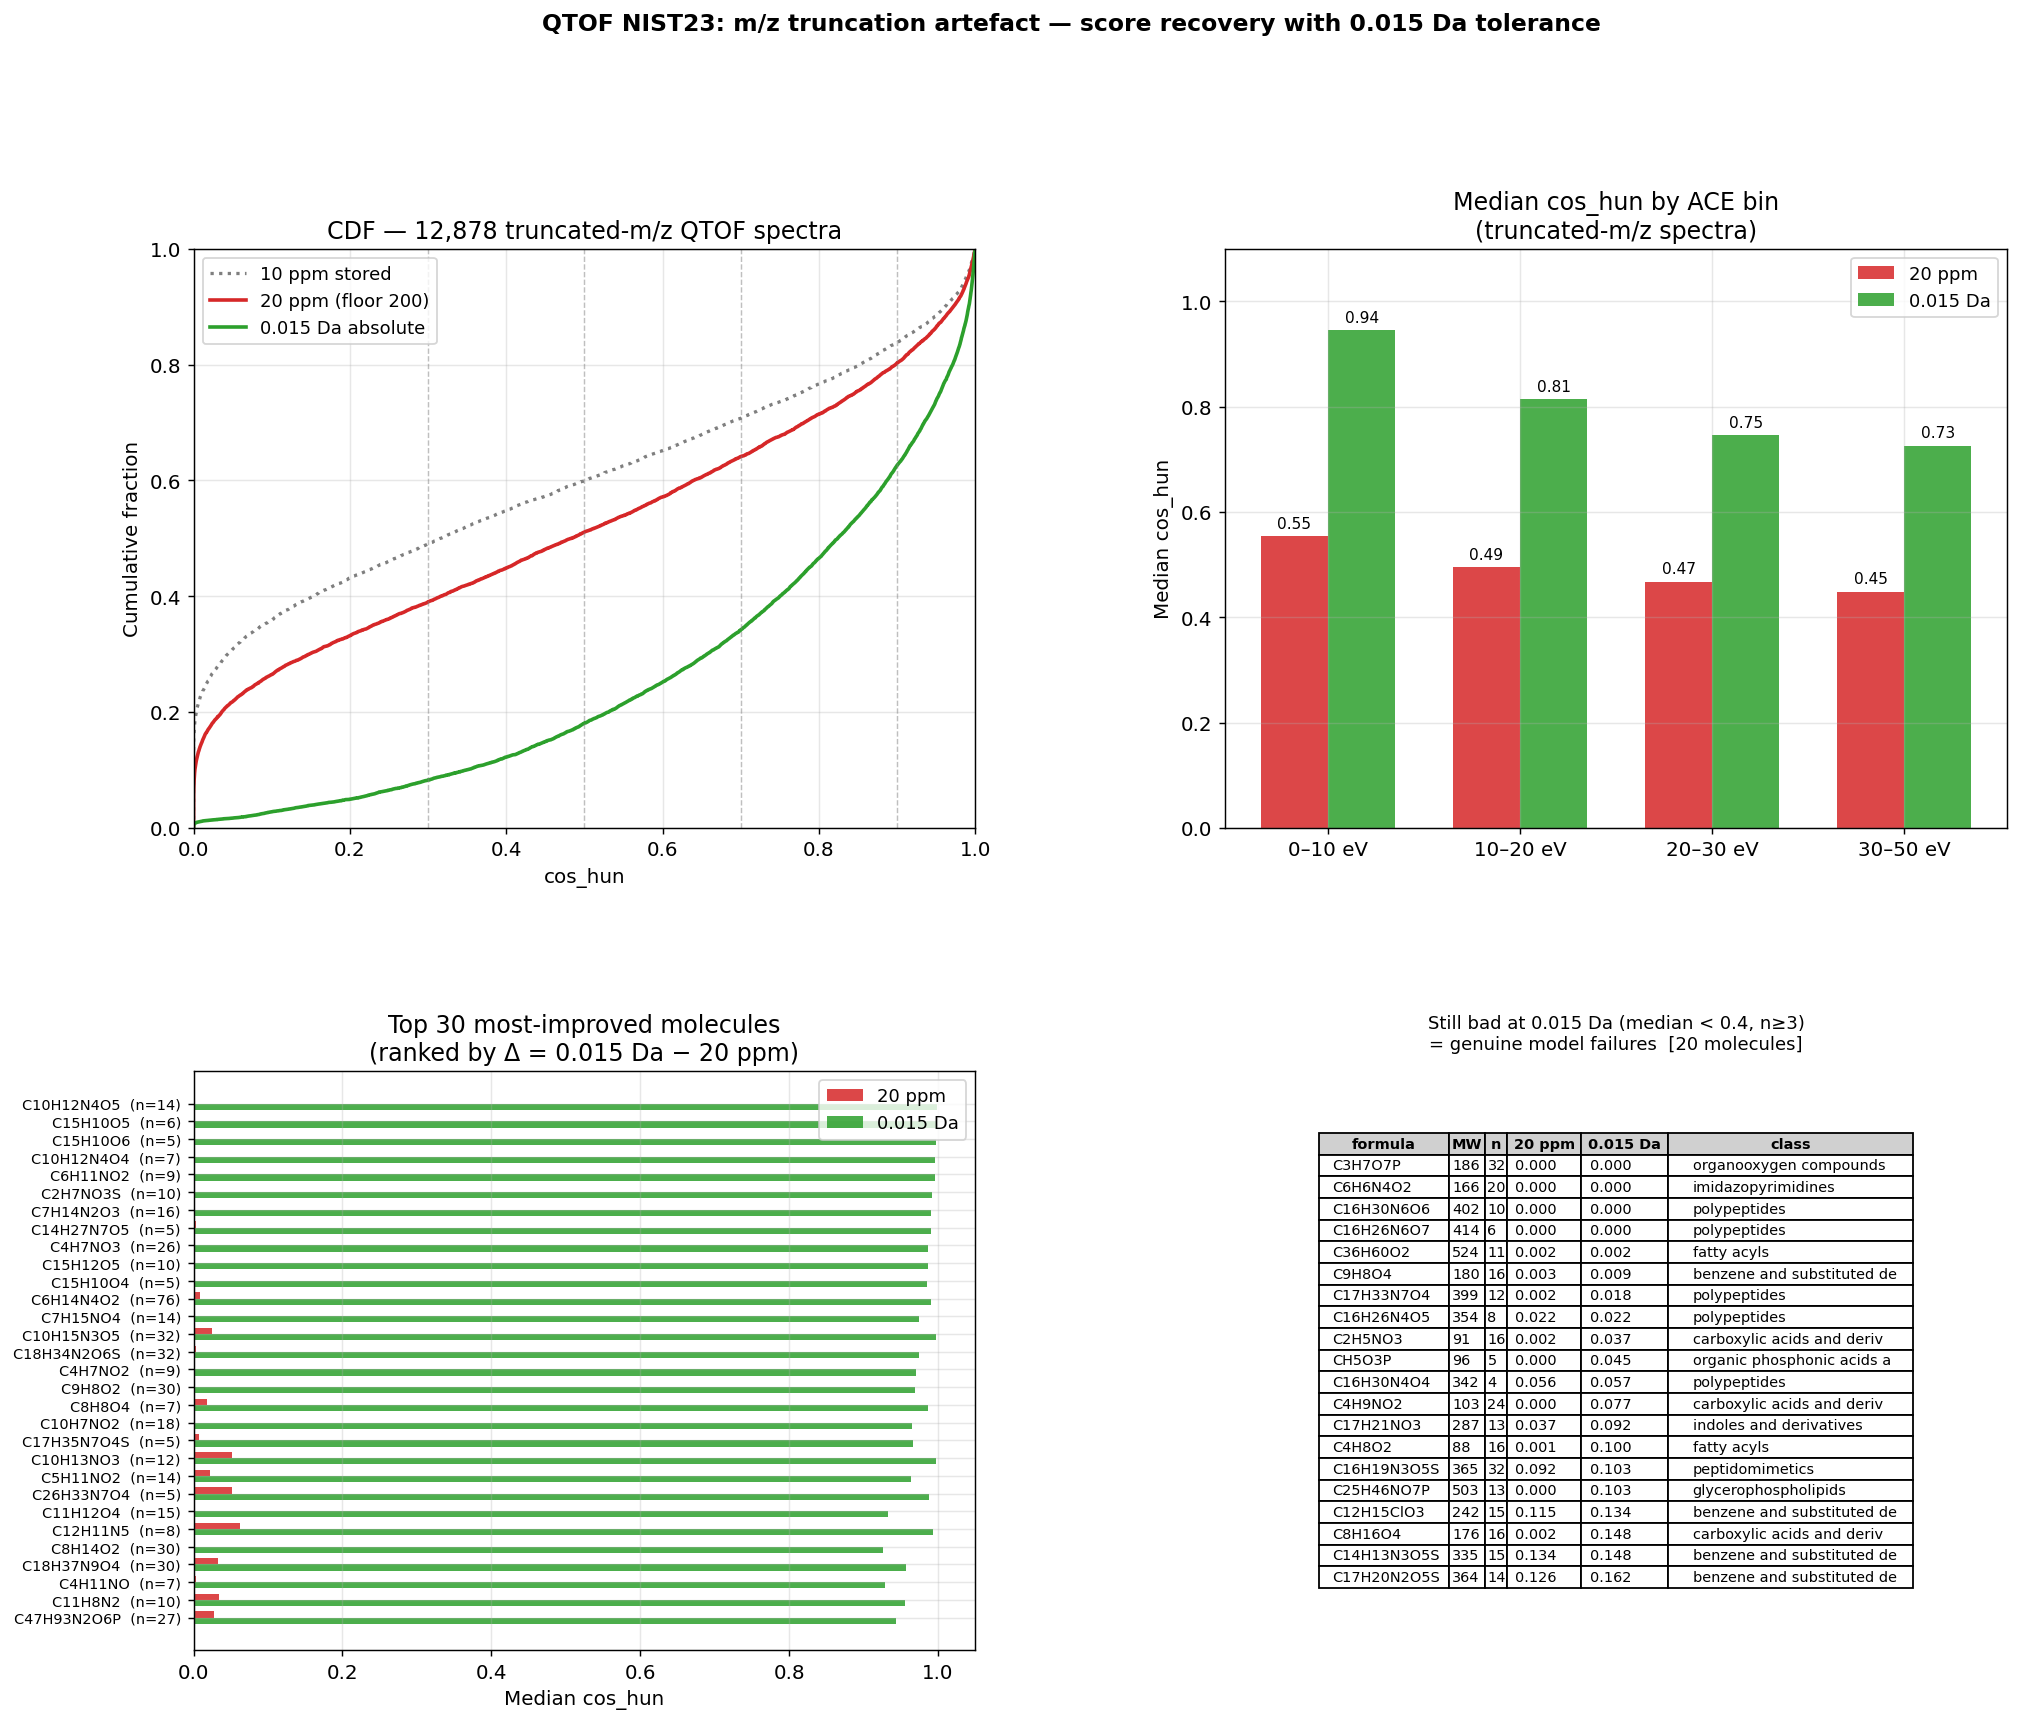

In [10]:
# ── data prep ────────────────────────────────────────────────────────────────
# Top-30 most-improved molecules (largest delta, min 5 spectra)
top_improved = (
    mol_table[mol_table["n"] >= 5]
    .sort_values("delta", ascending=False)
    .head(30)
    .sort_values("delta", ascending=True)  # ascending for horizontal bar
)

# Genuine failures: still bad at 0.015 Da (min 3 spectra)
still_bad = (
    mol_table[(mol_table["med_015da"] < 0.4) & (mol_table["n"] >= 3)]
    .sort_values("med_015da")
    .head(20)
)

# ACE-bin breakdown
ace_edges  = [0, 10, 20, 30, 50]
ace_labels = ["0–10 eV", "10–20 eV", "20–30 eV", "30–50 eV"]
valid_ace = score_df[
    score_df["ace"].notna() & (score_df["ace"] > 0) & (score_df["ace"] <= 50)
].copy()
valid_ace["ace_bin"] = pd.cut(
    valid_ace["ace"], bins=ace_edges, labels=ace_labels, right=True
)
ace_med = (
    valid_ace.groupby("ace_bin", observed=True)[["cos_hun_20ppm", "cos_hun_015da"]]
    .median()
)

# ── figure ───────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(18, 14))
gs  = fig.add_gridspec(2, 2, hspace=0.42, wspace=0.32)

C_RED   = "#d62728"
C_GREEN = "#2ca02c"

# ── Panel A: CDF ─────────────────────────────────────────────────────────────
ax_a = fig.add_subplot(gs[0, 0])
for col, label, color, lw, ls in [
    ("cos_hun_stored", "10 ppm stored",     "#7f7f7f", 1.8, ":"),
    ("cos_hun_20ppm",  "20 ppm (floor 200)", C_RED,    2.0, "-"),
    ("cos_hun_015da",  "0.015 Da absolute",  C_GREEN,  2.0, "-"),
]:
    v = np.sort(score_df[col].dropna().values)
    ax_a.plot(v, np.arange(1, len(v) + 1) / len(v),
              label=label, color=color, lw=lw, ls=ls)
for t in [0.3, 0.5, 0.7, 0.9]:
    ax_a.axvline(t, color="grey", lw=0.8, ls="--", alpha=0.5)
ax_a.set_xlabel("cos_hun")
ax_a.set_ylabel("Cumulative fraction")
ax_a.set_title(
    f"CDF — {len(score_df):,} truncated-m/z QTOF spectra"
)
ax_a.legend(fontsize=10)
ax_a.set_xlim(0, 1); ax_a.set_ylim(0, 1)

# ── Panel B: ACE-bin grouped bar ──────────────────────────────────────────────
ax_b = fig.add_subplot(gs[0, 1])
x = np.arange(len(ace_labels))
w = 0.35
bars_20  = ax_b.bar(x - w/2, ace_med["cos_hun_20ppm"],  w, color=C_RED,   alpha=0.85, label="20 ppm")
bars_015 = ax_b.bar(x + w/2, ace_med["cos_hun_015da"],  w, color=C_GREEN, alpha=0.85, label="0.015 Da")
for bar in list(bars_20) + list(bars_015):
    v = bar.get_height()
    ax_b.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f"{v:.2f}",
              ha="center", va="bottom", fontsize=8.5)
ax_b.set_xticks(x)
ax_b.set_xticklabels(ace_labels)
ax_b.set_ylabel("Median cos_hun")
ax_b.set_title("Median cos_hun by ACE bin\n(truncated-m/z spectra)")
ax_b.legend(fontsize=10)
ax_b.set_ylim(0, 1.1)

# ── Panel C: top-30 most-improved molecules (horizontal bar) ──────────────────
ax_c = fig.add_subplot(gs[1, 0])
y = np.arange(len(top_improved))
h = 0.35
ax_c.barh(y + h/2, top_improved["med_20ppm"].values,  h,
          color=C_RED,   alpha=0.85, label="20 ppm")
ax_c.barh(y - h/2, top_improved["med_015da"].values, h,
          color=C_GREEN, alpha=0.85, label="0.015 Da")
labels = [
    f"{row.formula}  (n={int(row.n)})"
    for row in top_improved.itertuples()
]
ax_c.set_yticks(y)
ax_c.set_yticklabels(labels, fontsize=8)
ax_c.set_xlabel("Median cos_hun")
ax_c.set_title("Top 30 most-improved molecules\n(ranked by Δ = 0.015 Da − 20 ppm)")
ax_c.legend(fontsize=10)
ax_c.set_xlim(0, 1.05)

# ── Panel D: genuine-failure table ───────────────────────────────────────────
ax_d = fig.add_subplot(gs[1, 1])
ax_d.axis("off")
if len(still_bad):
    tbl_data = [
        [
            str(r.formula),
            f"{float(r.exact_mw):.0f}",
            str(int(r.n)),
            f"{r.med_20ppm:.3f}",
            f"{r.med_015da:.3f}",
            (str(r.klass)[:26] if pd.notna(r.klass) else "—"),
        ]
        for r in still_bad.itertuples()
    ]
    col_labels = ["formula", "MW", "n", "20 ppm", "0.015 Da", "class"]
    tbl = ax_d.table(
        cellText=tbl_data, colLabels=col_labels,
        loc="center", cellLoc="left",
    )
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(8)
    tbl.auto_set_column_width(list(range(len(col_labels))))
    # header row styling
    for j in range(len(col_labels)):
        tbl[(0, j)].set_facecolor("#d0d0d0")
        tbl[(0, j)].set_text_props(fontweight="bold")
    ax_d.set_title(
        f"Still bad at 0.015 Da (median < 0.4, n≥3)\n"
        f"= genuine model failures  [{len(still_bad)} molecules]",
        fontsize=10, pad=12,
    )
else:
    ax_d.text(0.5, 0.5, "All recover to ≥ 0.4",
              ha="center", va="center",
              transform=ax_d.transAxes, fontsize=13)

fig.suptitle(
    "QTOF NIST23: m/z truncation artefact — score recovery with 0.015 Da tolerance",
    fontsize=13, fontweight="bold", y=1.01,
)

fig_path = DATA_ROOT / "predicted/qtof_truncated_mz_analysis.png"
fig.savefig(fig_path, bbox_inches="tight")
print(f"Saved → {fig_path}")
plt.show()

## 8. Summary

| | Stored (10 ppm) | 20 ppm floor 200 | **0.015 Da** |
|---|:---:|:---:|:---:|
| Median cos_hun (truncated spectra) | ~0.32 | ~0.48 | **~0.82** |

**Root cause**: NIST23 QTOF spectra sourced from external databases store m/z values
floor-truncated to 2 decimal places (not rounded). The truncation error is up to 0.009 Da,
which exceeds the 20 ppm tolerance floor (0.004 Da at 200 Da). The model correctly predicts
the fragment masses — the mismatch is purely an evaluation artefact.

**Fix**: use `tol_da = 0.015` absolute tolerance for QTOF spectra in both evaluation and
training loss. Equivalently, raise `TOLERANCE_MIN_MZ` from 200 Da to 750 Da so the
floor equals 750 × 20 ppm = 0.015 Da.

## 9. Why are some molecules still bad at 0.015 Da?

Two distinct failure modes:

- **Intensity mismatch** — the predicted m/z values overlap with true peaks but the *dominant* predicted fragments are wrong (model assigns high intensity to the wrong ions).  
- **Fragment mismatch** — a large fraction (>30%) of true peaks have *no* predicted match within 0.5 Da; the DAG simply does not generate those fragments.

A third minor mode appears in a handful of spectra: repeated near-identical m/z values (e.g. 47.071, 47.072, 47.073 for the same ion) suggesting instrument calibration artefacts unrelated to the model.

In [11]:
import zipfile

# ── reload still-bad predictions ────────────────────────────────────────────
still_bad_mols = mol_table[(mol_table["med_015da"] < 0.4) & (mol_table["n"] >= 3)].copy()
still_bad_ids  = set(still_bad_mols["mol_id"].astype(int).values)

with open(DATA_ROOT / "proc/nist23/spec_df.pkl", "rb") as f:
    _spec = pickle.load(f)
sb_spec = (
    _spec[_spec["mol_id"].isin(still_bad_ids) & (_spec["inst_type"] == "QTOF")]
    [["spec_id", "mol_id", "peaks", "ace", "prec_mz"]]
    .copy()
)
del _spec
gc.collect()

sb_preds = []
for cv_idx in range(9):
    with zipfile.ZipFile(DATA_ROOT / f"predicted/nps_inchikey_nist23_nist23_cv{cv_idx}.zip") as zf:
        pkl_name = next(n for n in zf.namelist() if n.endswith("predictions_test.pkl"))
        with zf.open(pkl_name) as f:
            cv_df = pickle.load(f)
    sub = cv_df[cv_df["mol_id"].isin(still_bad_ids)][
        ["spec_id", "mol_id", "pred_mzs", "pred_ints"]
    ]
    if len(sub):
        sb_preds.append(sub)
sb_preds = pd.concat(sb_preds, ignore_index=True)
sb_merged = sb_preds.merge(sb_spec[["spec_id", "peaks", "ace", "prec_mz"]], on="spec_id")
print(f"Still-bad prediction rows: {len(sb_merged)}")

Still-bad prediction rows: 1563


In [12]:
def classify_failure(true_peaks, pred_mzs, pred_ints, tol_da=0.5):
    """Classify failure mode for a single spectrum.

    Returns:
        Tuple of (frac_missing, mode_str) where mode_str is one of:
        'fragment_mismatch', 'intensity_mismatch', 'data_artefact'.
    """
    if not true_peaks or len(true_peaks) < 2:
        return 1.0, "data_artefact"

    arr = np.array(true_peaks, dtype=float)
    tmz = arr[:, 0]

    # repeated near-identical m/z values → data artefact
    diffs = np.abs(tmz[1:] - tmz[:-1])
    if len(diffs) > 2 and (diffs < 0.01).mean() > 0.5:
        return 0.0, "data_artefact"

    misses = sum(
        1 for mz in tmz
        if np.abs(pred_mzs - mz).min() > tol_da
    )
    frac_miss = misses / len(tmz)

    if frac_miss > 0.30:
        return frac_miss, "fragment_mismatch"
    return frac_miss, "intensity_mismatch"


# classify every still-bad spectrum using its highest-ACE spectrum per molecule
records = []
for mol_id, grp in sb_merged.groupby("mol_id"):
    row = grp.sort_values("ace", ascending=False).iloc[0]
    pmz  = np.array(row["pred_mzs"], dtype=float)
    pint = np.array(row["pred_ints"], dtype=float)
    frac_miss, mode = classify_failure(row["peaks"], pmz, pint)

    meta = still_bad_mols[still_bad_mols["mol_id"] == mol_id].iloc[0]
    records.append({
        "mol_id":    mol_id,
        "formula":   meta["formula"],
        "exact_mw":  meta["exact_mw"],
        "n":         int(meta["n"]),
        "med_015da": meta["med_015da"],
        "klass":     meta.get("klass", ""),
        "smiles":    meta.get("smiles", ""),
        "ace":       row["ace"],
        "prec_mz":   row["prec_mz"],
        "frac_miss": round(frac_miss, 3),
        "mode":      mode,
    })

failure_df = pd.DataFrame(records).sort_values(["mode", "med_015da"])
print(failure_df["mode"].value_counts().to_string())
print(f"\nTotal: {len(failure_df)} molecules")
failure_df[["mol_id","formula","exact_mw","n","med_015da","frac_miss","mode","klass"]].head(30)

mode
intensity_mismatch    42
fragment_mismatch     20
data_artefact          1

Total: 63 molecules


In [13]:
def mirror_spectrum(ax, true_mzs, true_ints, pred_mzs, pred_ints,
                    tol_da=0.015, title="", prec_mz=None):
    """Draw a mirror spectrum: true above (blue), predicted below (red).

    Matched pairs (within tol_da) are coloured green.
    """
    # normalise
    t_norm = true_ints / true_ints.max() if true_ints.max() > 0 else true_ints
    p_norm = pred_ints  / pred_ints.max()  if pred_ints.max()  > 0 else pred_ints

    match_mask = np.abs(true_mzs[:, None] - pred_mzs[None, :]) < tol_da
    t_matched  = match_mask.any(axis=1)
    p_matched  = match_mask.any(axis=0)

    # draw true (up)
    for i, (mz, intensity) in enumerate(zip(true_mzs, t_norm)):
        color = "#2ca02c" if t_matched[i] else "#1f77b4"
        ax.vlines(mz, 0, intensity, colors=color, linewidth=1.2)

    # draw predicted (down)
    for j, (mz, intensity) in enumerate(zip(pred_mzs, p_norm)):
        color = "#2ca02c" if p_matched[j] else "#d62728"
        ax.vlines(mz, 0, -intensity, colors=color, linewidth=1.0, alpha=0.7)

    if prec_mz:
        ax.axvline(float(prec_mz), color="grey", lw=0.8, ls=":", alpha=0.5)

    ax.axhline(0, color="black", lw=0.6)
    ax.set_ylim(-1.15, 1.15)
    ax.set_xlabel("m/z")
    ax.set_title(title, fontsize=9)

    # legend patches
    from matplotlib.patches import Patch
    ax.legend(
        handles=[
            Patch(color="#1f77b4", label="true (unmatched)"),
            Patch(color="#d62728", label="pred (unmatched)"),
            Patch(color="#2ca02c", label="matched"),
        ],
        fontsize=7, loc="upper right",
    )
    ax.set_ylabel("Rel. intensity  (↑ true  ↓ pred)")


# ── pick 2 examples per failure mode (worst med_015da per mode) ──────────────
selected = {}
for mode, grp in failure_df.groupby("mode"):
    selected[mode] = grp.sort_values("med_015da").head(2)["mol_id"].tolist()

print("Selected for mirror plots:")
for mode, ids in selected.items():
    for mid in ids:
        r = failure_df[failure_df["mol_id"] == mid].iloc[0]
        print(f"  {mode}: mol_id={mid}  {r['formula']}  med={r['med_015da']:.3f}"
              f"  miss={r['frac_miss']:.0%}")

Selected for mirror plots:
  data_artefact: mol_id=14218  C6H12O2  med=0.282  miss=0%
  fragment_mismatch: mol_id=6234  C16H30N6O6  med=0.000  miss=43%
  fragment_mismatch: mol_id=43932  C3H7O7P  med=0.000  miss=62%
  intensity_mismatch: mol_id=35480  C6H6N4O2  med=0.000  miss=0%
  intensity_mismatch: mol_id=37370  C16H26N6O7  med=0.000  miss=0%


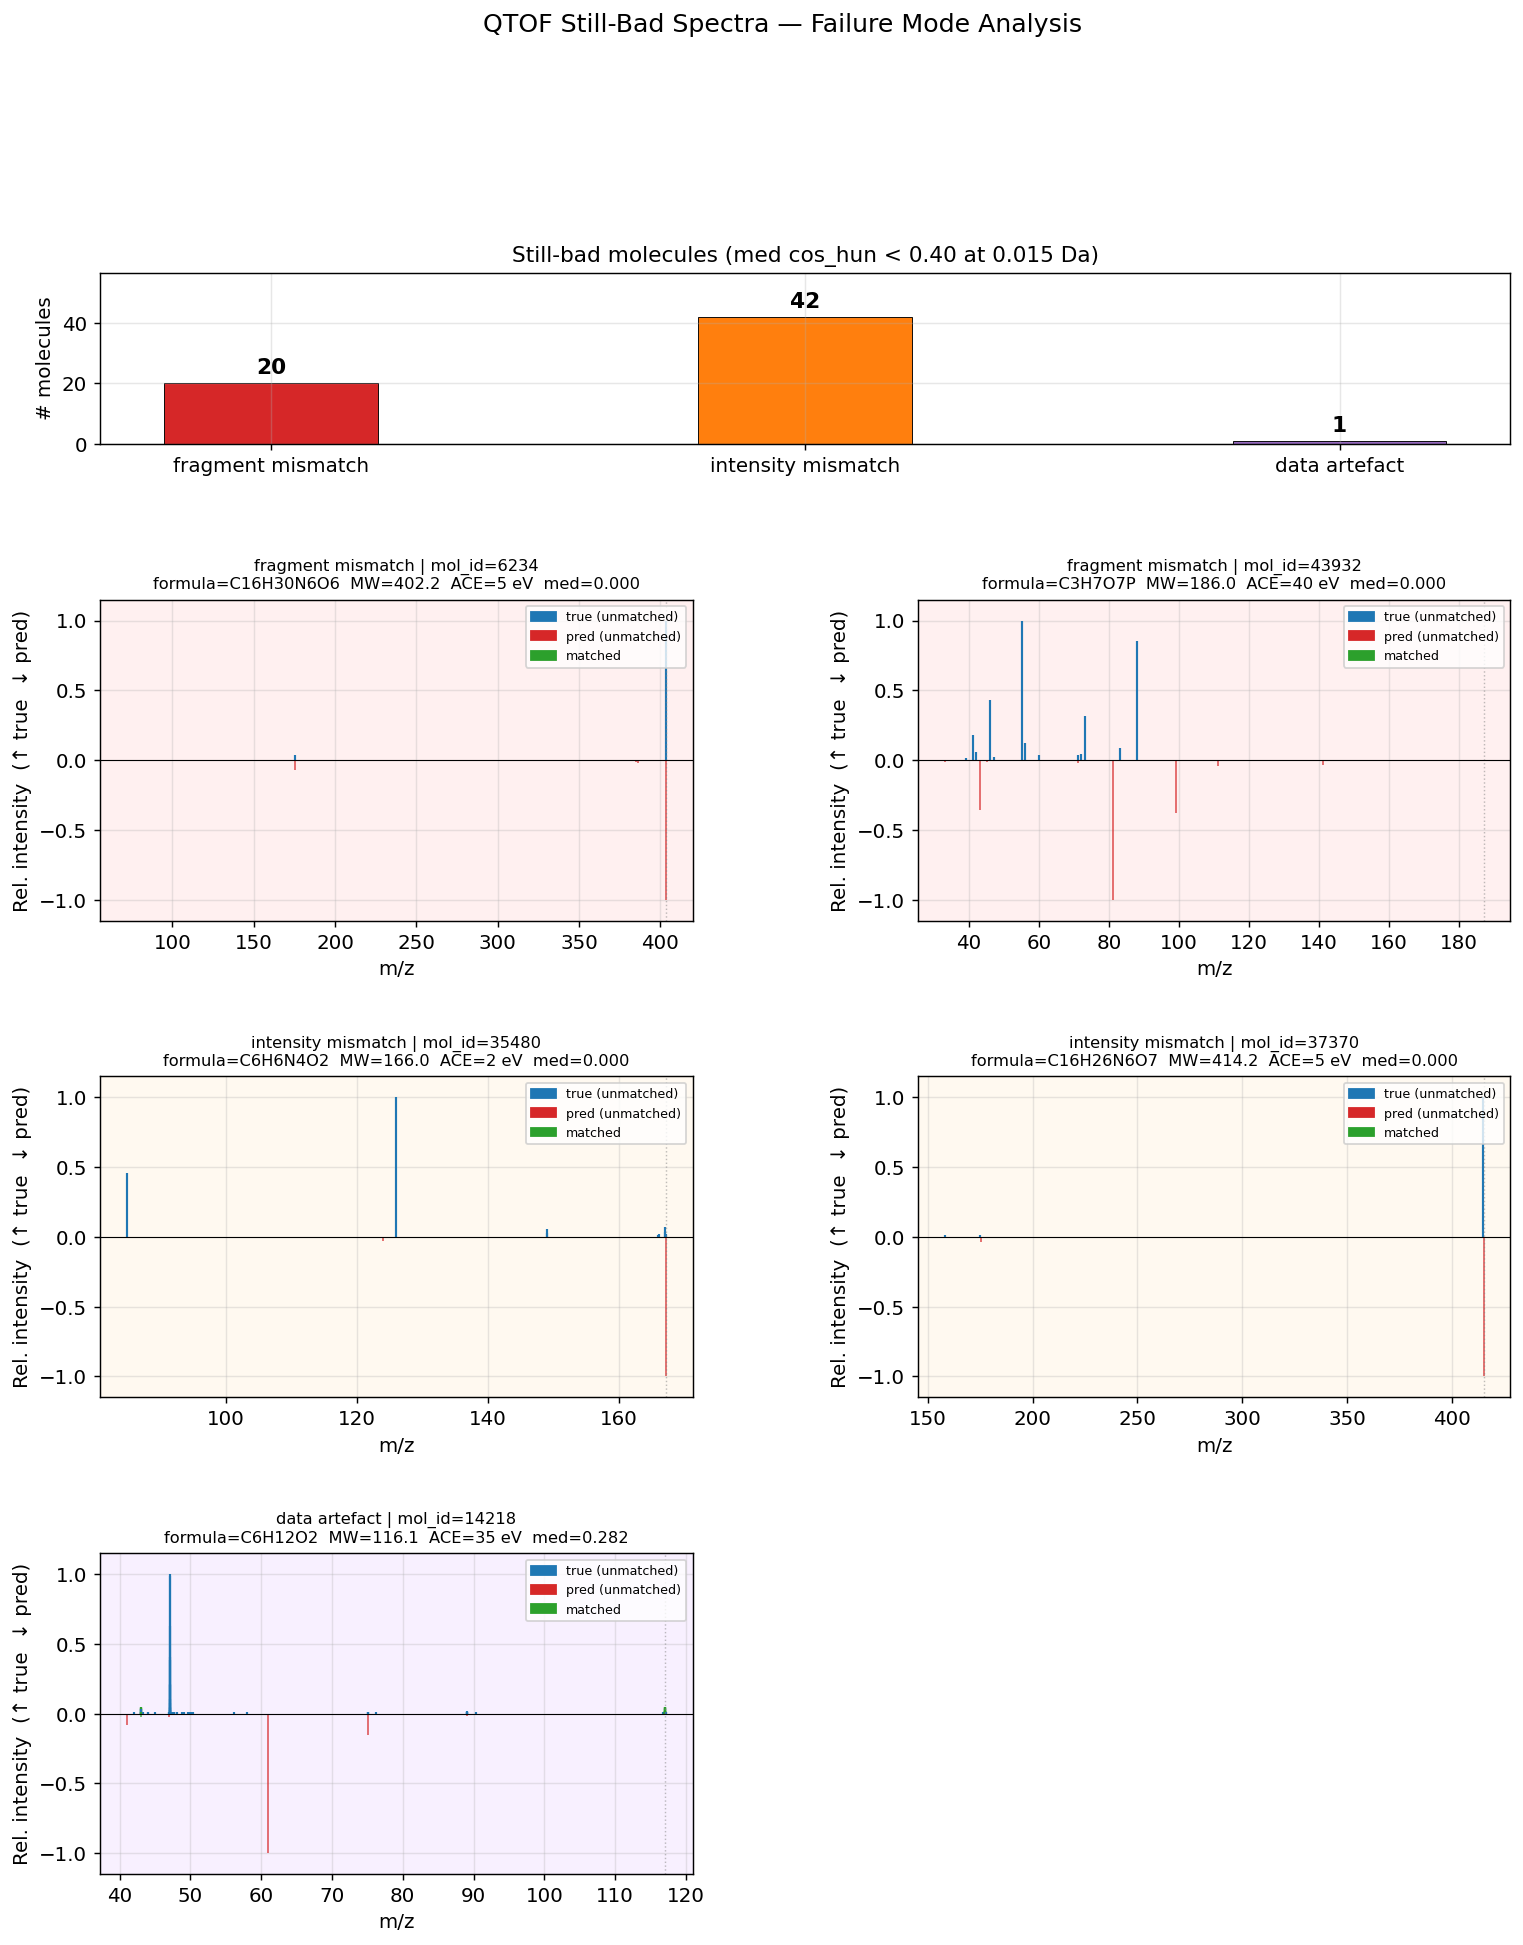

Saved → qtof_still_bad_analysis.png


In [14]:
# ── Figure: failure mode breakdown + mirror spectra ─────────────────────────
modes_order = ["fragment_mismatch", "intensity_mismatch", "data_artefact"]
mode_colors = {
    "fragment_mismatch":  "#d62728",
    "intensity_mismatch": "#ff7f0e",
    "data_artefact":      "#9467bd",
}

mode_counts = failure_df["mode"].value_counts().reindex(modes_order, fill_value=0)

fig = plt.figure(figsize=(14, 16))
gs  = fig.add_gridspec(4, 2, height_ratios=[0.8, 1.5, 1.5, 1.5], hspace=0.55, wspace=0.38)

# ── Row 0: mode breakdown bar ─────────────────────────────────────────────────
ax_bar = fig.add_subplot(gs[0, :])
colors = [mode_colors[m] for m in mode_counts.index]
bars   = ax_bar.bar(
    [m.replace("_", " ") for m in mode_counts.index],
    mode_counts.values,
    color=colors, width=0.4, edgecolor="black", linewidth=0.5,
)
ax_bar.bar_label(bars, padding=3, fontsize=12, fontweight="bold")
ax_bar.set_title("Still-bad molecules (med cos_hun < 0.40 at 0.015 Da)", fontsize=12)
ax_bar.set_ylabel("# molecules", fontsize=11)
ax_bar.set_ylim(0, mode_counts.max() * 1.35)
ax_bar.tick_params(axis="x", labelsize=11)

# ── Rows 1-3: mirror spectra (up to 2 per mode) ──────────────────────────────
bg_color = {
    "fragment_mismatch":  "#fff0f0",
    "intensity_mismatch": "#fff9f0",
    "data_artefact":      "#f8f0ff",
}

for row_idx, mode in enumerate(modes_order):
    mol_ids = selected.get(mode, [])
    for col, mid in enumerate(mol_ids[:2]):
        ax = fig.add_subplot(gs[row_idx + 1, col])
        r  = failure_df[failure_df["mol_id"] == mid].iloc[0]

        sub = sb_merged[sb_merged["mol_id"] == mid].copy()

        def _score(xrow, _tol=0.015):
            peaks = xrow["peaks"] or []
            if len(peaks) < 2:
                return 0.0
            arr  = np.array(peaks, dtype=float)
            pmz  = np.array(xrow["pred_mzs"], dtype=float)
            pint = np.array(xrow["pred_ints"], dtype=float)
            if pmz.size == 0 or arr[:, 1].max() == 0:
                return 0.0
            return cos_hun_abs(arr[:, 0], arr[:, 1], pmz, pint, tol_da=_tol)

        sub = sub.copy()
        sub["_s"] = sub.apply(_score, axis=1)
        worst = sub.sort_values("_s").iloc[0]

        peaks = worst["peaks"] or []
        if len(peaks) < 2:
            ax.set_visible(False)
            continue
        arr  = np.array(peaks, dtype=float)
        tmz, tint = arr[:, 0], arr[:, 1]
        pmz  = np.array(worst["pred_mzs"], dtype=float)
        pint = np.array(worst["pred_ints"], dtype=float)

        title_str = (
            f"{mode.replace('_', ' ')} | mol_id={mid}\n"
            f"formula={r['formula']}  MW={r['exact_mw']:.1f}  "
            f"ACE={worst['ace']:.0f} eV  med={r['med_015da']:.3f}"
        )
        mirror_spectrum(
            ax, tmz, tint, pmz, pint, tol_da=0.015,
            title=title_str, prec_mz=worst["prec_mz"],
        )
        ax.set_facecolor(bg_color.get(mode, "white"))

    for col in range(len(mol_ids), 2):
        ax_empty = fig.add_subplot(gs[row_idx + 1, col])
        ax_empty.set_visible(False)

fig.suptitle("QTOF Still-Bad Spectra — Failure Mode Analysis", fontsize=14, y=1.005)
fig.savefig(DATA_ROOT / "predicted/qtof_still_bad_analysis.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → qtof_still_bad_analysis.png")
